# 02 · Frozen Street-View Retrieval

Evaluates frozen `dinov2-small` image retrieval from a 2,000-image OSV-5M train gallery on the 18 `pilot_dev` queries, outputting the Top-1 coordinate while retaining Top-10 candidates. Inference sees raw RGB pixels only; ground-truth coordinates are used exclusively for scoring.

Run `python3 -B scripts/prepare_gallery.py` and `python3 -B scripts/pack_retrieval.py` locally, upload `retrieval_2000_upload/` to Colab T4, and execute this notebook to verify the pipeline and coverage diagnostics.


In [1]:
import json
import os
import sys
import zipfile
from pathlib import Path

import torch

GALLERY_COUNT = 2000
assert torch.cuda.is_available(), "Select Kernel → Colab → GPU → T4"
DEVICE = f"cuda:0"
print(f"GPU: {torch.cuda.get_device_name()} | PyTorch: {torch.__version__}")
RUN = Path(f"/content/geoguessr-retrieval-{GALLERY_COUNT}")
RUN.mkdir(parents=True, exist_ok=True)
os.environ["HF_HOME"] = str(RUN / "hf-cache")
os.environ["HF_HUB_DISABLE_XET"] = "1"

GPU: Tesla T4 | PyTorch: 2.14.1+cu130


In [2]:
def find_upload(name):
    archives = list(Path("/content").rglob(name))
    if len(archives) != 1:
        raise FileNotFoundError(f"Expected exactly one uploaded {name}; found {len(archives)}")
    return archives[0]

def extract_bundle(path):
    with zipfile.ZipFile(path) as bundle:
        for info in bundle.infolist():
            if not (RUN / info.filename).resolve().is_relative_to(RUN.resolve()):
                raise ValueError(f"Unsafe ZIP member in {path.name}")
        bundle.extractall(RUN)

extract_bundle(find_upload(f"retrieval_code_{GALLERY_COUNT}.zip"))
for part in json.loads((RUN / "gallery_parts.json").read_text()):
    extract_bundle(find_upload(part))
sys.path.insert(0, str(RUN))
from retrieval import run_retrieval

RESULTS = RUN / "results"
print(f"Gallery and pilot_dev ready in {RUN}")

Gallery and pilot_dev ready in /content/geoguessr-retrieval-2000


## Four-Stage Diagnostic

`gallery_within_25` measures raw gallery coverage, `raw_top100_within_25` measures visual Top-100 recall, `geo_top10_within_25` measures how many valid candidates survive geographic aggregation, and `top1_within_25` measures final Top-1 accuracy (all counts out of 18 queries).


In [3]:
metrics = run_retrieval(RUN / "gallery", RUN / "query", RESULTS, device=DEVICE)

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Encoding 2000 images with facebook/dinov2-small on cuda:0
Encoded 32/2000
Encoded 352/2000
Encoded 672/2000
Encoded 992/2000
Encoded 1312/2000
Encoded 1632/2000
Encoded 1952/2000
Encoded 2000/2000
Encoding 18 images with facebook/dinov2-small on cuda:0
Encoded 18/18
source,n,gallery_within_25,raw_top100_within_25,geo_top10_within_25,top1_within_25,top1_within_200,median_km,mean_world_points
all,18,2,0,0,0,2,800.5708730750669,2814.3037522960117
osv5m,9,1,0,0,0,1,714.5593984747181,2536.071692774632
panoramax,9,1,0,0,0,1,886.5823476754155,3092.535811817391



## Qualitative Examples · Queries, Ground Truth & Geographic Candidates


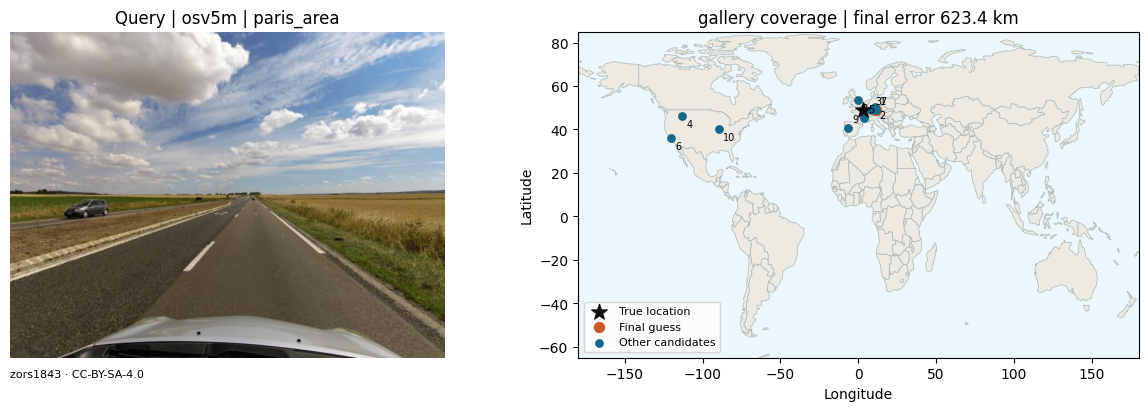

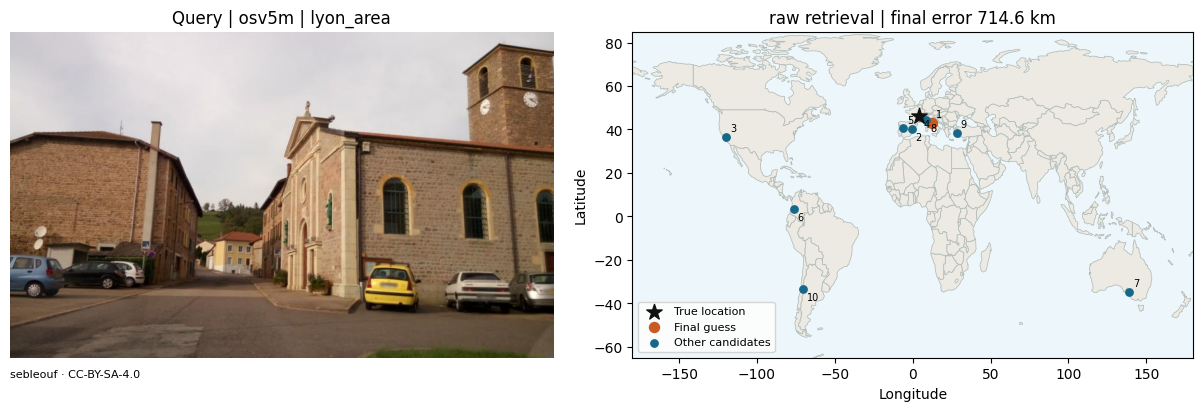

In [4]:
from collections import OrderedDict
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from PIL import Image, ImageOps

queries = {row["id"]: row for line in (RUN / "query/pilot_dev.jsonl").read_text().splitlines()
           if (row := json.loads(line))}
predictions = [json.loads(line) for line in (RESULTS / "candidates.jsonl").read_text().splitlines()]
examples = OrderedDict()
for result in predictions:
    examples.setdefault(result["first_lost_stage"], result)
countries = json.loads((RUN / "map.geojson").read_text())["features"]
outlines = [polygon[0] for country in countries for geometry in [country["geometry"]]
            for polygon in (geometry["coordinates"] if geometry["type"] == "MultiPolygon"
                            else [geometry["coordinates"]])]

for result in examples.values():
    sample = queries[result["id"]]
    fig, (photo, world) = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    with Image.open(RUN / "query" / sample["image"]) as image:
        photo.imshow(ImageOps.exif_transpose(image).convert("RGB"))
    photo.set_title(f"Query | {sample['source']} | {sample['region']}")
    photo.set_axis_off()
    photo.text(0, -0.06, f"{sample['attribution']} · {sample['license']}", transform=photo.transAxes, fontsize=8)
    world.set_facecolor("#edf6fa")
    world.add_collection(PolyCollection(outlines, facecolor="#eceae2", edgecolor="#b3bcb9", linewidth=0.55))
    world.scatter(result["longitude"], result["latitude"], s=135, marker="*", color="#111111", label="True location", zorder=4)
    for rank, candidate in enumerate(result["candidates"], 1):
        x, y = candidate["longitude"], candidate["latitude"]
        world.scatter(x, y, s=52 if rank == 1 else 28, zorder=3,
                      color="#c95a22" if rank == 1 else "#166889",
                      label="Final guess" if rank == 1 else "Other candidates" if rank == 2 else None)
        world.annotate(str(rank), (x, y), xytext=(3, 4 if rank % 2 else -8), textcoords="offset points",
                       fontsize=7, zorder=4)
    world.set(xlim=(-180, 180), ylim=(-65, 85), xlabel="Longitude", ylabel="Latitude")
    world.legend(loc="lower left", fontsize=8)
    world.set_title(f"{result['first_lost_stage'].replace('_', ' ')} | final error {result['distance_km']:,.1f} km")
    plt.show()
    plt.close(fig)

In [5]:
import shutil

archive = shutil.make_archive(f"/content/frozen-retrieval-{GALLERY_COUNT}-pilot_dev-results",
                              "zip", root_dir=RESULTS)
print(f"Download to SSD results/: {archive}")

Download to SSD results/: /content/frozen-retrieval-2000-pilot_dev-results.zip
